# Step 1: Install Requirements

In [ ]:

!pip install ultralytics
!pip install roboflow

import torch
import os
from IPython.display import Image, clear_output

print(f"Setup complete. Using torch {torch.__version__} ({torch.cuda.get_device_properties(0).name if torch.cuda.is_available() else 'CPU'})")


Setup complete. Using torch 2.6.0+cu124 (Tesla T4)


# Step 2: Assemble Our Dataset

In order to train our custom model, we need to assemble a dataset of representative images with bounding box annotations around the objects that we want to detect. And we need our dataset to be in YOLOv5 format.

In Roboflow, you can choose between two paths:

* Convert an existing dataset to YOLOv5 format. Roboflow supports over [30 formats object detection formats](https://roboflow.com/formats) for conversion.
* Upload raw images and annotate them in Roboflow with [Roboflow Annotate](https://docs.roboflow.com/annotate).

# Annotate

![](https://roboflow-darknet.s3.us-east-2.amazonaws.com/roboflow-annotate.gif)

# Version

![](https://roboflow-darknet.s3.us-east-2.amazonaws.com/robolfow-preprocessing.png)


In [ ]:
from roboflow import Roboflow
from google.colab import userdata
secret_value = userdata.get('ROBOFLOW_API_KEY')

rf = Roboflow(api_key=secret_value, model_format="yolov8", notebook="ultralytics")

In [ ]:
os.environ["DATASET_DIRECTORY"] = "/content/datasets"

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="ROBOFLOW_API_KEY")
project = rf.workspace("leo-ueno").project("people-detection-o4rdr")
version = project.version(9)
dataset = version.download("yolov8")



loading Roboflow workspace...
loading Roboflow project...


# Step 3: Train Our Custom YOLOv8 model

Here, we are able to pass a number of arguments:
- **img:** define input image size
- **batch:** determine batch size
- **epochs:** define the number of training epochs. (Note: often, 3000+ are common here!)
- **data:** Our dataset locaiton is saved in the `dataset.location`
- **weights:** specify a path to weights to start transfer learning from. Here we choose the generic COCO pretrained checkpoint.
- **cache:** cache images for faster training

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data=dataset.location + "/data.yaml",
    imgsz=416,
    batch=16,
    epochs=5,
    cache=True
)



Ultralytics 8.3.158 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/People-Detection-9/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train7, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose

train: Scanning /content/datasets/People-Detection-9/train/labels.cache... 15210 images, 1932 backgrounds, 0 corrupt: 100%|██████████| 15210/15210 [00:00<?, ?it/s]

train: /content/datasets/People-Detection-9/train/images/2007_000187_jpg.rf.6072bb3923494a7afb8648ba483324fd.jpg: 23 duplicate labels removed
train: /content/datasets/People-Detection-9/train/images/2007_000999_jpg.rf.6c08f70e15d4b331a62dd733f71a31ef.jpg: 7 duplicate labels removed
train: /content/datasets/People-Detection-9/train/images/2007_002260_jpg.rf.67b39e42171c963a3427b19a2abe68b4.jpg: 19 duplicate labels removed
train: /content/datasets/People-Detection-9/train/images/2008_003417_jpg.rf.f31d813882efbf61f9f5526453e177e3.jpg: 1 duplicate labels removed
train: /content/datasets/People-Detection-9/train/images/2008_003522_jpg.rf.0c7864f40841e847ba3fb26e08efd3e3.jpg: 1 duplicate labels removed
train: /content/datasets/People-Detection-9/train/images/2008_006554_jpg.rf.f803f4b634de852ff949e04c8e89ced5.jpg: 1 duplicate labels removed
train: /content/datasets/People-Detection-9/train/images/2009_002733_jpg.rf.a2dac53f2d02cd54c047dc7af456e088.jpg: 1 duplicate labels removed
WARNING ⚠️ 

WARNING ⚠️ train: 7.8GB RAM required to cache images with 50% safety margin but only 2.9/12.7GB available, not caching images
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 9.7±3.9 MB/s, size: 70.8 KB)


val: Scanning /content/datasets/People-Detection-9/valid/labels.cache... 1431 images, 61 backgrounds, 0 corrupt: 100%|██████████| 1431/1431 [00:00<?, ?it/s]

...

                   all       1431      10660      0.749      0.519      0.581      0.332



5 epochs completed in 1.024 hours.
Optimizer stripped from runs/detect/train7/weights/last.pt, 22.5MB
Optimizer stripped from runs/detect/train7/weights/best.pt, 22.5MB

Validating runs/detect/train7/weights/best.pt...
Ultralytics 8.3.158 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 45/45 [00:11<00:00,  3.83it/s]


                   all       1431      10660      0.748       0.52      0.581      0.332
Speed: 0.3ms preprocess, 1.8ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to runs/detect/train7


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78e878ac9250>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

# Evaluate Custom YOLOv8 Detector Performance
Training losses and performance metrics are saved to Tensorboard and also to a logfile.

If you are new to these metrics, the one you want to focus on is `mAP_0.5` - learn more about mean average precision [here](https://blog.roboflow.com/mean-average-precision/).

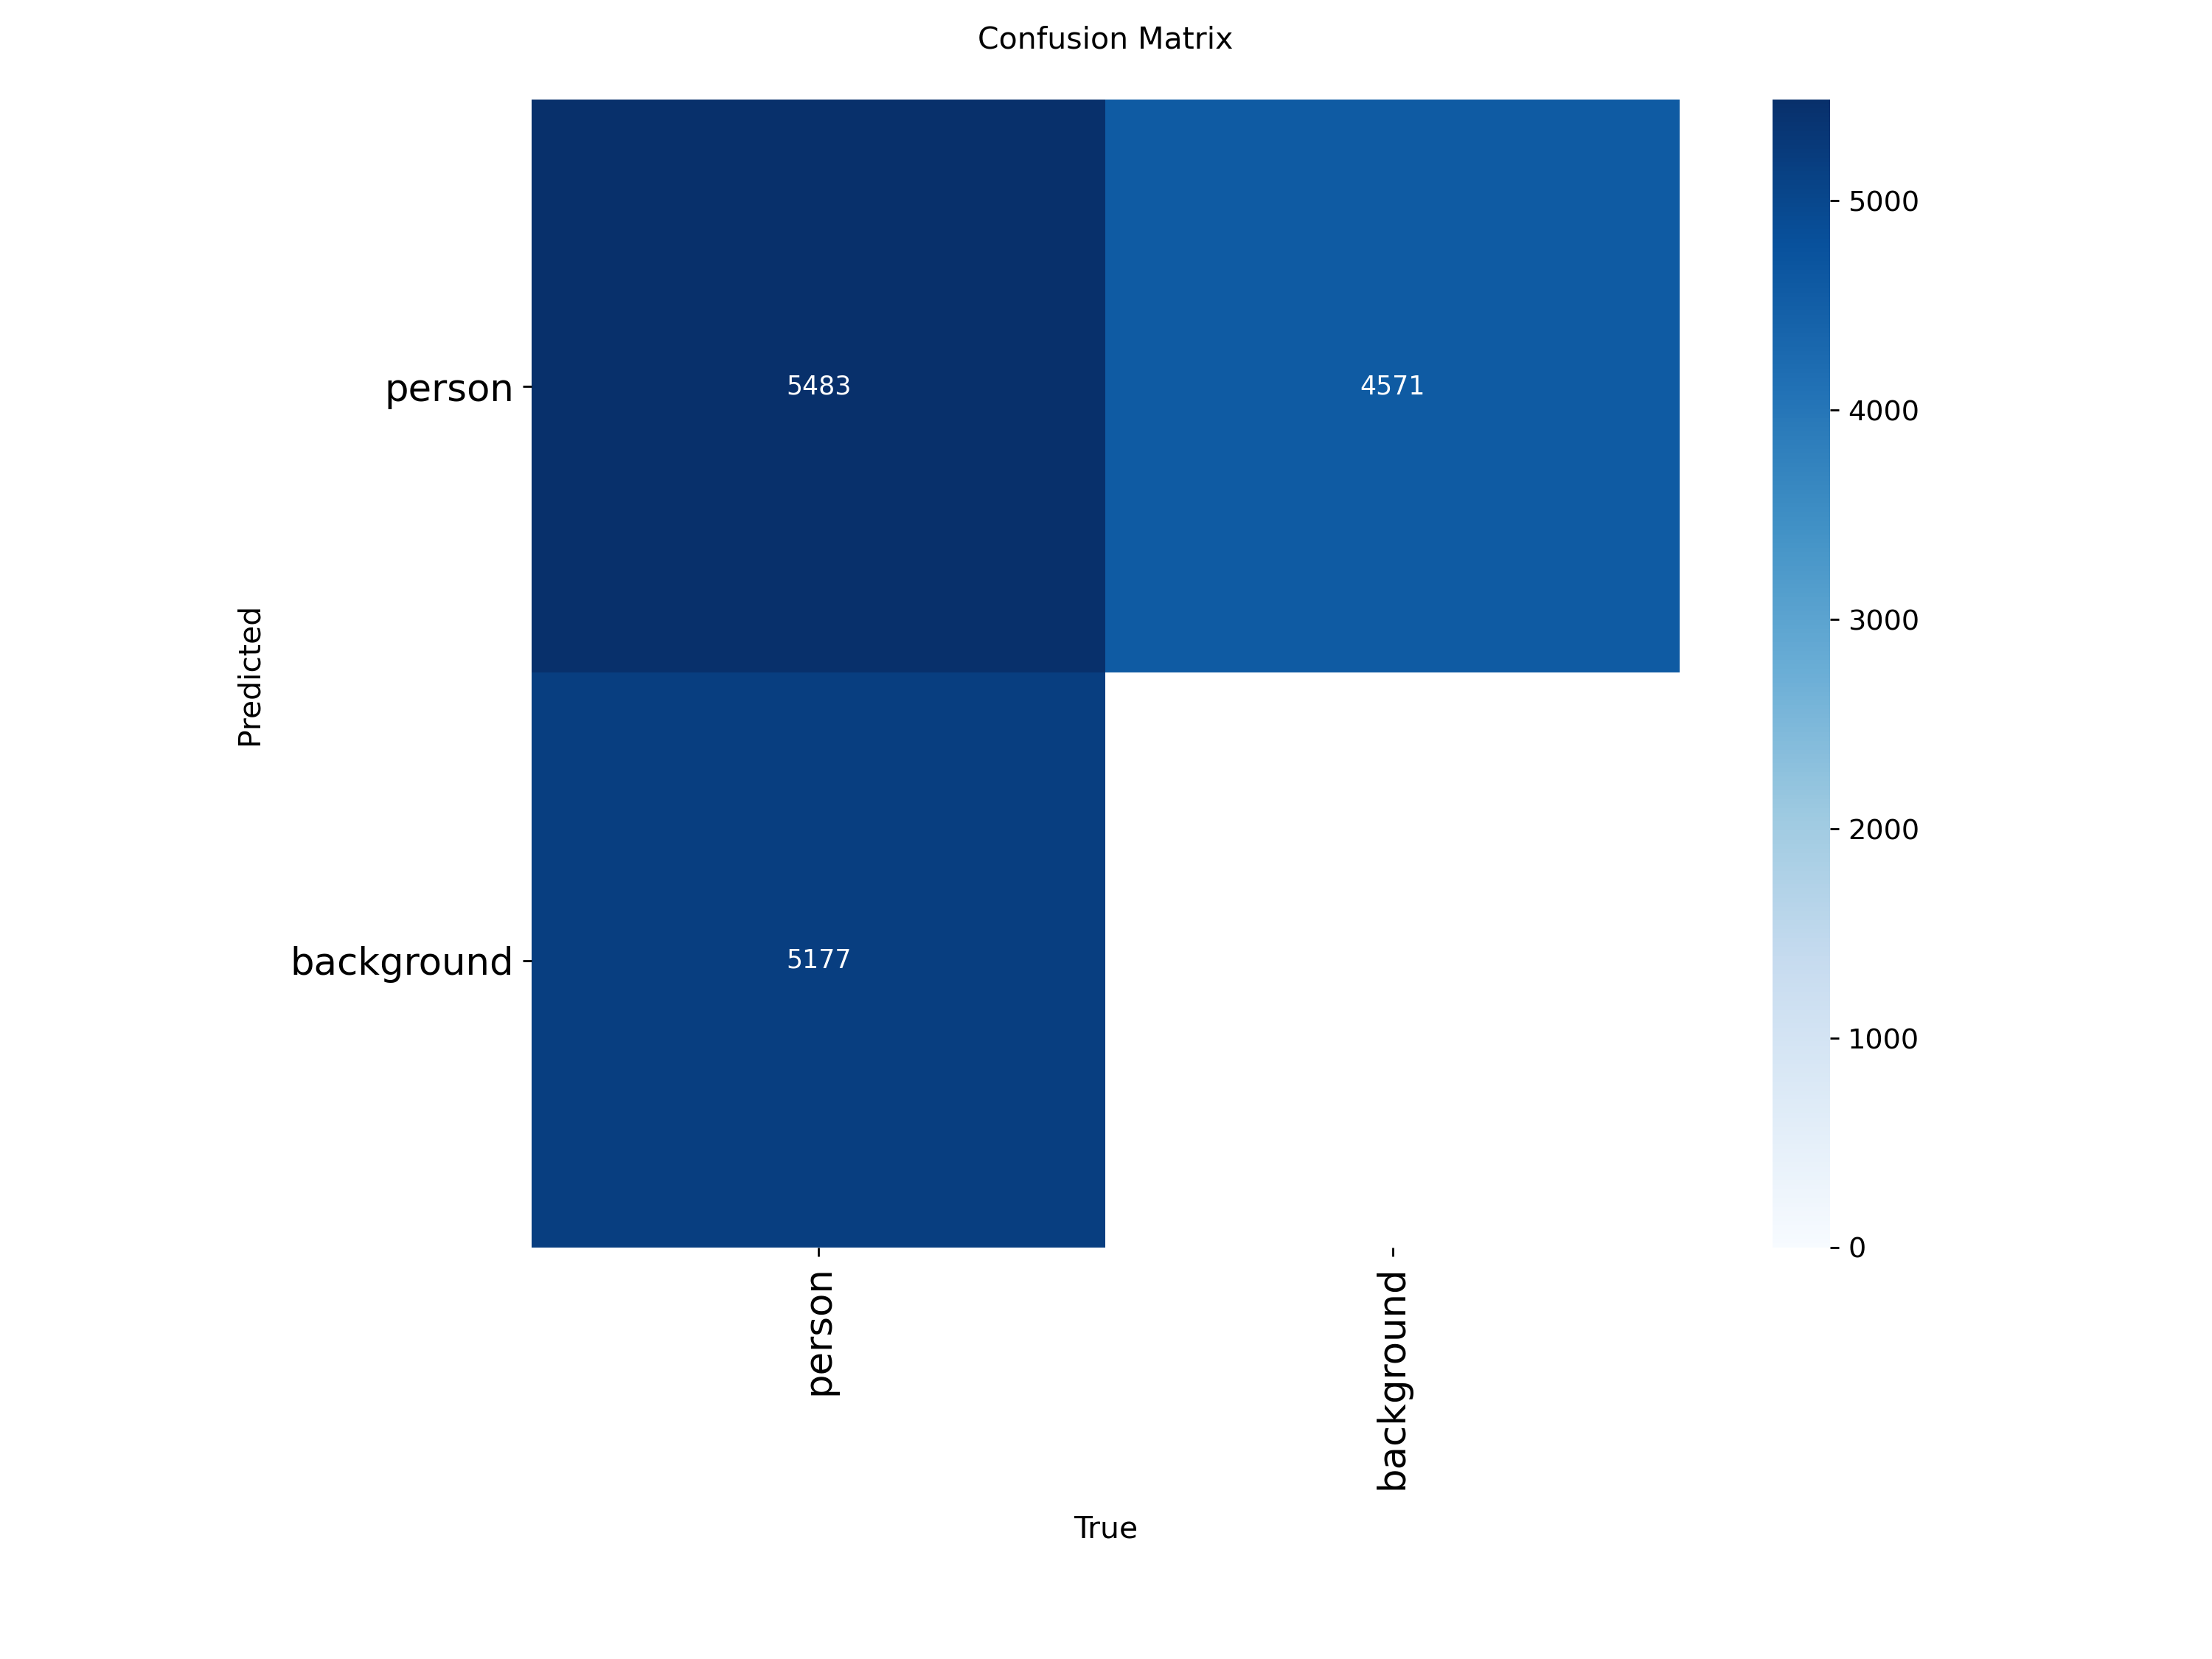

In [ ]:
Image(filename="/content/runs/detect/train/confusion_matrix.png")

#Run Inference  With Trained Weights
Run inference with a pretrained checkpoint on contents of `test/images` folder downloaded from Roboflow.

In [ ]:
results = model.predict(
    source="/content/datasets/People-Detection-9/test/images",
    conf=0.5,
    iou=0.45,
    save=True,
    imgsz=640
)


image 1/760 /content/datasets/People-Detection-9/test/images/0000540_jpg.rf.d1b964542ac8df27835f1348ebcac01a.jpg: 512x640 2 persons, 14.3ms
image 2/760 /content/datasets/People-Detection-9/test/images/000054_r-2_jpg.rf.23723f3554a328733717247da135acc8.jpg: 512x640 2 persons, 13.2ms
image 3/760 /content/datasets/People-Detection-9/test/images/000070_jpg.rf.5898e9817249586892b429970c485b29.jpg: 384x640 23 persons, 11.5ms
image 4/760 /content/datasets/People-Detection-9/test/images/000071_jpg.rf.b134f02af03ac3e9ada819f9010aebce.jpg: 384x640 21 persons, 10.7ms
image 5/760 /content/datasets/People-Detection-9/test/images/000075_jpg.rf.81b226a4f4ca1e5463ba31e203c9a029.jpg: 384x640 22 persons, 10.8ms
image 6/760 /content/datasets/People-Detection-9/test/images/000077_jpg.rf.86614d2155ccf19053745e610adca4ab.jpg: 384x640 26 persons, 10.7ms
image 7/760 /content/datasets/People-Detection-9/test/images/000079_jpg.rf.1ec8b32716b68fc22ed1078a66ef611a.jpg: 384x640 24 persons, 10.7ms
image 8/760 /con

In [ ]:
import glob
from IPython.display import Image, display

image_files = glob.glob('runs/detect/train5/*.jpg')[:4]
for imageName in image_files:
    display(Image(filename=imageName))
    print("\n")

# Conclusion and Next Steps

Congratulations! You've trained a custom YOLOv8 model to recognize your custom objects.

To improve you model's performance, we recommend first interating on your datasets coverage and quality. See this guide for [model performance improvement](https://github.com/ultralytics/yolov5/wiki/Tips-for-Best-Training-Results).

To deploy your model to an application, see this guide on [exporting your model to deployment destinations](https://github.com/ultralytics/yolov5/issues/251).

Once your model is in production, you will want to continually iterate and improve on your dataset and model via [active learning](https://blog.roboflow.com/what-is-active-learning/).

In [ ]:
model = YOLO("runs/detect/train/weights/best.pt")

metrics = model.val()

precision = metrics.box.pr
recall = metrics.box.re
map_50 = metrics.box.map50
map_50_95 = metrics.box.map
f1_score = 2 * (precision * recall) / (precision + recall)
inference_time = metrics.speed['inference']

display(Markdown(f"""

| Model     | Precision | Recall | F1 Score | mAP@0.5 | mAP@0.5:0.95 | Inference Time (ms) |
|-----------|-----------|--------|----------|---------|--------------|---------------------|
| YOLOv8    | {precision:.2f}    | {recall:.2f} | {f1_score:.2f}   | {map_50:.2f}   | {map_50_95:.2f}     | {inference_time:.2f}             |
"""))

In [ ]:
from google.colab import files
files.download('runs/detect/train3/weights/best.pt')